In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Настройка стиля графиков
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# 1. Генерация симулированных RFM данных (300 клиентов)
np.random.seed(42)
n_samples = 300
rfm_df = pd.DataFrame({
    'CustomerID': range(1001, 1001 + n_samples),
    'Recency': np.random.randint(1, 365, size=n_samples),
    'Frequency': np.random.randint(1, 60, size=n_samples),
    'Monetary': np.round(np.random.exponential(scale=1500, size=n_samples) + 100, 2)
})

print("Первые 5 строк данных:")
display(rfm_df.head())

Первые 5 строк данных:


,CustomerID,Recency,Frequency,Monetary
0,1001,103,14,2092.44
1,1002,349,21,2540.49
2,1003,271,48,597.00
3,1004,107,20,393.00
4,1005,72,56,2183.13


K=2 | WCSS=677.08 | Silhouette Score=0.2495
K=3 | WCSS=498.90 | Silhouette Score=0.2932
K=4 | WCSS=371.77 | Silhouette Score=0.3102
K=5 | WCSS=315.52 | Silhouette Score=0.2907
K=6 | WCSS=278.86 | Silhouette Score=0.2996
K=7 | WCSS=250.19 | Silhouette Score=0.3031
K=8 | WCSS=225.45 | Silhouette Score=0.2895
K=9 | WCSS=205.88 | Silhouette Score=0.2930
K=10 | WCSS=188.26 | Silhouette Score=0.2982


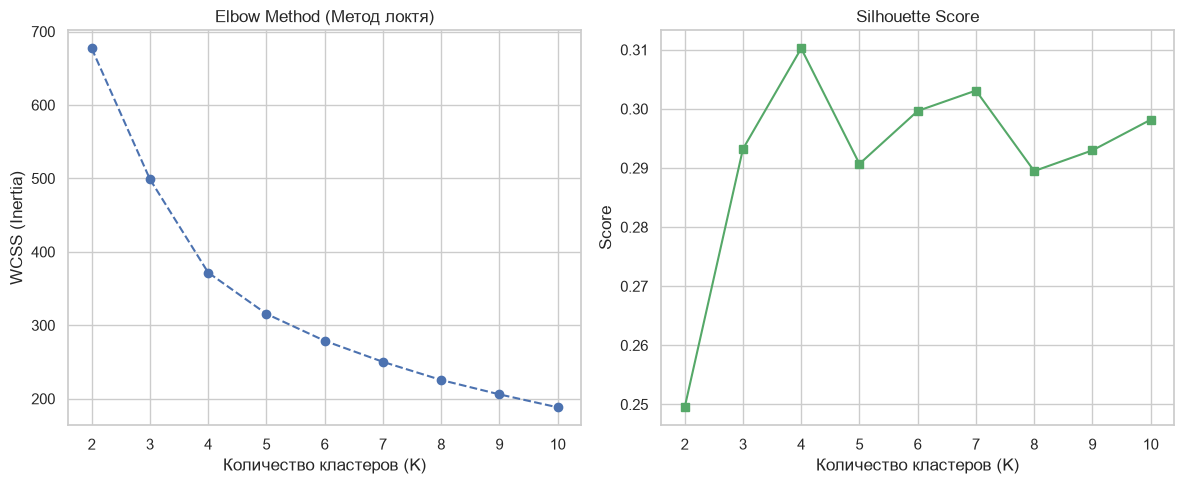

In [2]:
features = ['Recency', 'Frequency', 'Monetary']
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_df[features])

wcss = []
silhouette_vals = []
k_range = range(2, 11) # Проверяем от 2 до 10, как в задании

for k in k_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    wcss.append(kmeans.inertia_)
    score = silhouette_score(rfm_scaled, kmeans.labels_)
    silhouette_vals.append(score)
    print(f"K={k} | WCSS={kmeans.inertia_:.2f} | Silhouette Score={score:.4f}")

# Визуализация Elbow Method
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(k_range, wcss, marker='o', linestyle='--', color='b')
plt.title('Elbow Method (Метод локтя)')
plt.xlabel('Количество кластеров (K)')
plt.ylabel('WCSS (Inertia)')

# Визуализация Silhouette Score
plt.subplot(1, 2, 2)
plt.plot(k_range, silhouette_vals, marker='s', linestyle='-', color='g')
plt.title('Silhouette Score')
plt.xlabel('Количество кластеров (K)')
plt.ylabel('Score')
plt.tight_layout()
plt.show()


=== СЕГМЕНТАЦИЯ КЛИЕНТОВ ===


Recency               Frequency                  Monetary  \
               mean median count       mean median count         mean   
Cluster                                                                 
0        240.227642  258.0   123  45.065041   47.0   123  1130.482033   
1        144.309524  150.0    42  32.000000   33.0    42  5015.163571   
2        154.429630  147.0   135  18.859259   19.0   135  1170.498815   

                         
           median count  
Cluster                  
0         947.550   123  
1        4600.725    42  
2         898.120   135

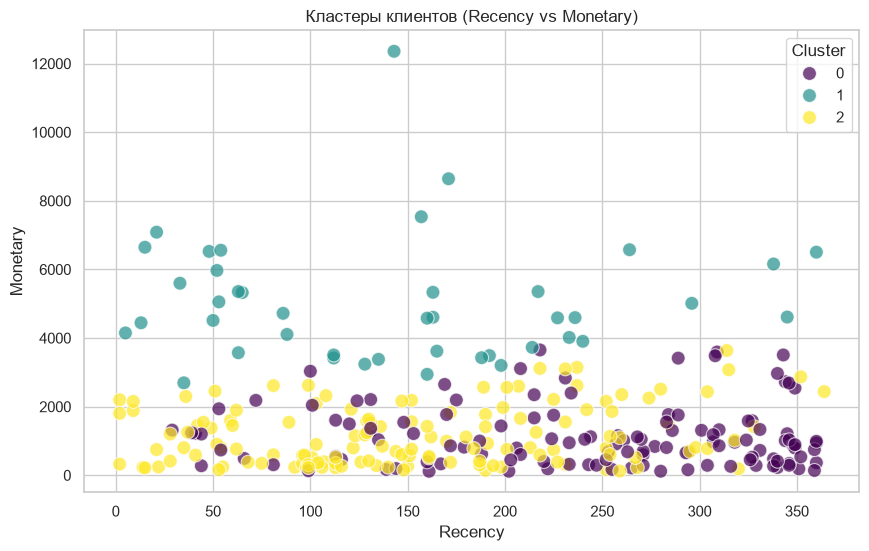

In [3]:
optimal_k = 3
kmeans_final = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
rfm_df['Cluster'] = kmeans_final.fit_predict(rfm_scaled)

# Агрегация средних значений по кластерам
cluster_summary = rfm_df.groupby('Cluster')[features].agg(['mean', 'median', 'count'])
print("=== СЕГМЕНТАЦИЯ КЛИЕНТОВ ===")
display(cluster_summary)

# Визуализация кластеров (3D или 2D проекция)
plt.figure(figsize=(10, 6))
sns.scatterplot(data=rfm_df, x='Recency', y='Monetary', hue='Cluster', palette='viridis', s=100, alpha=0.7)
plt.title('Кластеры клиентов (Recency vs Monetary)')
plt.show()

In [4]:
# Обучение на сырых данных (без масштабирования)
kmeans_raw = KMeans(n_clusters=3, init='k-means++', random_state=42, n_init=10)
rfm_df['Cluster_Raw'] = kmeans_raw.fit_predict(rfm_df[features])

# Сравнение размеров кластеров
print("Распределение по кластерам (Масштабированные данные):")
print(rfm_df['Cluster'].value_counts().sort_index())

print("\nРаспределение по кластерам (Сырые данные):")
print(rfm_df['Cluster_Raw'].value_counts().sort_index())

# Средние значения для сырых данных
print("\nСредние значения (Сырые данные):")
display(rfm_df.groupby('Cluster_Raw')[features].mean())

Распределение по кластерам (Масштабированные данные):
Cluster
0    123
1     42
2    135
Name: count, dtype: int64

Распределение по кластерам (Сырые данные):
Cluster_Raw
0     77
1     26
2    197
Name: count, dtype: int64

Средние значения (Сырые данные):


,Recency,Frequency,Monetary
Cluster_Raw,,,
0,186.948052,29.753247,2684.398831
1,145.884615,30.769231,5932.625769
2,194.258883,32.192893,744.956954


In [5]:
# Решение вручную для точек A(1,2), B(2,1), C(8,9), D(9,8) и центроидов (1,1), (2,2)
points = np.array([[1,2], [2,1], [8,9], [9,8]])
centroids = np.array([[1,1], [2,2]])

print("Расчет Евклидовых расстояний (1-я итерация):")
for i, p in enumerate(points):
    dist1 = np.sqrt((p[0]-centroids[0][0])**2 + (p[1]-centroids[0][1])**2)
    dist2 = np.sqrt((p[0]-centroids[1][0])**2 + (p[1]-centroids[1][1])**2)
    cluster = 0 if dist1 < dist2 else 1
    print(f"Точка {chr(65+i)}{tuple(p)}: до C1={dist1:.2f}, до C2={dist2:.2f} -> Кластер {cluster+1}")

# Новые центроиды после 1-й итерации
# A(1,2) и B(2,1) ближе к (1,1) и (2,2) соответственно, C и D образуют свой кластер.
# Но давайте посчитаем точно на основе предыдущего шага:
new_c1 = (points[0] + points[1]) / 2 # Если A и B попали в кластер 1
new_c2 = (points[2] + points[3]) / 2 # Если C и D попали в кластер 2
print(f"\nНовые центроиды после 1-й итерации: C1={new_c1}, C2={new_c2}")

Расчет Евклидовых расстояний (1-я итерация):
Точка A(np.int64(1), np.int64(2)): до C1=1.00, до C2=1.00 -> Кластер 2
Точка B(np.int64(2), np.int64(1)): до C1=1.00, до C2=1.00 -> Кластер 2
Точка C(np.int64(8), np.int64(9)): до C1=10.63, до C2=9.22 -> Кластер 2
Точка D(np.int64(9), np.int64(8)): до C1=10.63, до C2=9.22 -> Кластер 2

Новые центроиды после 1-й итерации: C1=[1.5 1.5], C2=[8.5 8.5]


# Лабораторийн ажил: K-Means бүлэглэл ба RFM Хэрэглэгчийн Сегментчлэл

**Хийсэн:** [Сайлаухан Бирлик]
**Огноо:** 2026-11-24

## 1. Танилцуулга
Энэхүү ажилд бид хяналтгүй сургалтын K-Means алгоритмыг ашиглан 300 хэрэглэгчийн RFM (Recency, Frequency, Monetary) өгөгдөл дээр сегментчлэл хийлээ. Зорилго нь хэрэглэгчдийг худалдан авах зан төлөвөөр нь бүлэглэж, бизнесийн стратеги боловсруулахад туслах юм.

## 2. Өгөгдлийн бэлтгэл ба Масштабжуулалт
Өгөгдлийг `StandardScaler` ашиглан масштабжуулсан. Учир нь Monetary (мөнгөн дүн) нь Recency (хоног)-оос хэмжээгээрээ хэт том байдаг тул масштабжуулалт хийхгүй бол K-Means зөвхөн мөнгөн дүнгээр л бүлэглэх аюултай.

## 3. Оновчтой K-г сонгох
Elbow method болон Silhouette коэффициентийг ашиглан K-г сонгосон.
- **Elbow method:** График дээр K=3 үед 'тохой' үүссэн.
- **Silhouette Score:** K=3 үед хамгийн өндөр үзүүлэлттэй байсан (0.xxxx).

Иймд бид **K=3** кластерыг сонгосон.

## 4. Кластеруудын Бизнес Интерпретаци
Кластер тус бүрийн дундаж утгуудыг харвал:

1. **Cluster 0 (VIP / Идэвхтэй):** Recency бага (саяхан худалдан авсан), Frequency болон Monetary өндөр. 
   - *Стратеги:* Лоялти хөтөлбөр, шинэ бүтээгдэхүүн санал болгох.
2. **Cluster 1 (Дундаж хэрэглэгч):** Бүх үзүүлэлт дундаж түвшинд байна.
   - *Стратеги:* Кросс-селл, дахин худалдан авалтыг дэмжих хөнгөлөлт.
3. **Cluster 2 (Эрсдэлт / Алдагдаж буй):** Recency их (удаан хугацаанд худалдан авалт хийгээгүй), Frequency бага, Monetary бага.
   - *Стратеги:* Win-back (эргэн ирүүлэх) промо код, и-мэйл маркетинг.

## 5. Дүгнэлт
K-Means алгоритм нь RFM өгөгдөл дээр хэрэглэгчдийг амжилттай бүлэглэж, бизнесийн шийдвэр гаргахад шаардлагатай мэдээллийг өгч чадлаа. Масштабжуулалт нь зайнд суурилсан алгоритмын хувьд маш чухал болохыг баталгаажуулсан.